# Zomato Restaurant Clustering Using Machine Learning

##  Project Introduction

This project aims to analyze Zomato restaurant data
and customer reviews to identify meaningful restaurant
segments using Unsupervised Machine Learning.

##  Project Objectives

- Understand the restaurant and review datasets.
- Perform data cleaning and preprocessing.
- Conduct Exploratory Data Analysis (EDA).
- Perform feature engineering.
- Develop and evaluate clustering models.
- Build an interactive Streamlit dashboard.

##  Dataset Information

The project uses two datasets:

1. Zomato Restaurant Names and Metadata
2. Zomato Restaurant Reviews

##  Development Environment

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Streamlit
- Jupyter Notebook

## 1. Data Loading and Initial Inspection

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path            # File and directory management.

# Display setting
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("All required libraries imported.")           # To confirm the code is executing

All required libraries imported.


In [2]:
current_directory = Path.cwd()          # Current working directory
print("Current Working Directory:")
print(current_directory)            # Prints the location of the current directory

Current Working Directory:
d:\Documents\Projects\zomato-clustering-model\2. notebooks


In [3]:
project_root = Path.cwd().parent            # Project root directory
print("Project Root: ", project_root)
print()
print("Folders and Files available: ")
for item in project_root.iterdir():
    if item.is_dir():
        print(f"[FOLDER] {item.name}")
    else:
        print(f"[FILE] {item.name}")

Project Root:  d:\Documents\Projects\zomato-clustering-model

Folders and Files available: 
[FOLDER] .venv
[FOLDER] 1. data
[FOLDER] 2. notebooks
[FOLDER] 3. src
[FOLDER] 4. models
[FOLDER] 5. visualizations


In [4]:
# Inspection of 1. data folder
data_path = project_root / "1. data"
print("Contents of the folder: ")
for item in data_path.iterdir():
    if item.is_dir():
        print(f"[FOLDER] {item.name}")
    else: 
        print(f"[FILE] {item.name}")

Contents of the folder: 
[FOLDER] processed
[FOLDER] raw


In [5]:
# Inspection of raw folder
raw_data_path = data_path / "raw"
print("Files present in the raw folder: ")
print()
for file in raw_data_path.iterdir():
    print(file.name)

Files present in the raw folder: 

Zomato Restaurant names and Metadata.csv
Zomato Restaurant reviews.csv


In [6]:
# Defining paths of the given two datasets
metadata_file = raw_data_path / "Zomato Restaurant names and Metadata.csv"
reviews_file = raw_data_path / "Zomato Restaurant reviews.csv"

# Loading the given CSV files into panda DataFrames
metadata_df = pd.read_csv(metadata_file)
reviews_df = pd.read_csv(reviews_file)
print("Loading successful.")            # To confirm the execution of the code

Loading successful.


## 2. Data Quality Assessment

In [7]:
# Checking dimensionality
print("Metadata Dataset Shape: ", metadata_df.shape)
print("Reviews Dataset Shape: ", reviews_df.shape)

# Inspecting first 5 records
print("\nMetadata: ")
display(metadata_df.head())
print()
print("Reviews: ")
display(reviews_df.head())

Metadata Dataset Shape:  (105, 6)
Reviews Dataset Shape:  (10000, 7)

Metadata: 


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."



Reviews: 


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


In [8]:
# Structure Analysis
print("Metadata Information: ")
metadata_df.info()
print()
print("Reviews Information: ")
reviews_df.info()

Metadata Information: 
<class 'pandas.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Name         105 non-null    str  
 1   Links        105 non-null    str  
 2   Cost         105 non-null    str  
 3   Collections  51 non-null     str  
 4   Cuisines     105 non-null    str  
 5   Timings      104 non-null    str  
dtypes: str(6)
memory usage: 21.5 KB

Reviews Information: 
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Restaurant  10000 non-null  str  
 1   Reviewer    9962 non-null   str  
 2   Review      9955 non-null   str  
 3   Rating      9962 non-null   str  
 4   Metadata    9962 non-null   str  
 5   Time        9962 non-null   str  
 6   Pictures    10000 non-null  int64
dtypes: int64(1), str(6)
memory usage: 3.8 MB


In [9]:
# Missing values
print("Missing values in Metadata: ")
display(metadata_df.isnull().sum())
print()
print("Missing values in Reviews: ")
display(reviews_df.isnull().sum())

Missing values in Metadata: 


Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64


Missing values in Reviews: 


Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
dtype: int64

In [10]:
# Calculating missing values ratio
metadata_missing_ptage = (metadata_df.isnull().sum() / len(metadata_df)) * 100
reviews_missing_ptage = (reviews_df.isnull().sum() / len(reviews_df)) * 100
print("Missing Value Percentage")
print("\nFor Metadata(%) :- ")
display(metadata_missing_ptage.round(2))
print("For Reviews(%) :- ")
display(reviews_missing_ptage)

Missing Value Percentage

For Metadata(%) :- 


Name            0.00
Links           0.00
Cost            0.00
Collections    51.43
Cuisines        0.00
Timings         0.95
dtype: float64

For Reviews(%) :- 


Restaurant    0.00
Reviewer      0.38
Review        0.45
Rating        0.38
Metadata      0.38
Time          0.38
Pictures      0.00
dtype: float64

In [11]:
# Investigating missing values row-wise
print("Metadata rows containing missing values:")
display(metadata_df[metadata_df.isnull().any(axis=1)])          # Checking Metadata Rows
print()
print("Review rows containing missing values:")
display(reviews_df[reviews_df.isnull().any(axis=1)].head(10))           # Checking Review Rows

Metadata rows containing missing values:


,Name,Links,Cost,Collections,Cuisines,Timings
7,Shah Ghouse Spl Shawarma,https://www.zomato.com/hyderabad/shah-ghouse-s...,300,NaN,Lebanese,12 Noon to 12 Midnight
15,KFC,https://www.zomato.com/hyderabad/kfc-gachibowli,500,NaN,"Burger, Fast Food",11 AM to 11 PM
16,NorFest - The Dhaba,https://www.zomato.com/hyderabad/norfest-the-d...,550,NaN,North Indian,12 Noon to 10:30 PM
17,Hotel Zara Hi-Fi,https://www.zomato.com/hyderabad/hotel-zara-ga...,400,NaN,"Chinese, North Indian",11:30 AM to 1 AM
23,Amul,https://www.zomato.com/hyderabad/amul-gachibowli,150,NaN,"Ice Cream, Desserts",10 AM to 5 AM
25,Tiki Shack,https://www.zomato.com/hyderabad/tiki-shack-ga...,"1,000",NaN,Continental,"12Noon to 11PM (Mon-Thu),12Noon to 11:30PM (Fr..."
28,Behrouz Biryani,https://www.zomato.com/hyderabad/behrouz-birya...,600,NaN,"Mughlai, Biryani",10 AM to 1 AM
29,Hunger Maggi Point,https://www.zomato.com/hyderabad/hunger-maggi-...,200,NaN,Fast Food,4:30 PM to 5:30 AM
30,Pot Pourri,https://www.zomato.com/hyderabad/pot-pourri-ga...,900,NaN,"Andhra, South Indian, North Indian",NaN
33,Club Rogue,https://www.zomato.com/hyderabad/club-rogue-ga...,900,NaN,"North Indian, Fast Food",11 AM to 12 Midnight



Review rows containing missing values:


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
2360,Amul,Lakshmi Narayana,NaN,5,0 Reviews,7/29/2018 18:00,0
5799,Being Hungry,Surya,NaN,5,"4 Reviews , 4 Followers",7/19/2018 23:55,0
6449,Hyderabad Chefs,Madhurimanne97,NaN,5,1 Review,7/23/2018 16:29,0
6489,Hyderabad Chefs,Harsha,NaN,5,1 Review,7/8/2018 21:19,0
7954,Olive Garden,ARUGULLA PRAVEEN KUMAR,NaN,3,"1 Review , 1 Follower",8/9/2018 23:25,0
8228,Al Saba Restaurant,Suresh,NaN,5,1 Review,7/20/2018 22:42,0
8777,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8778,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8779,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8780,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0


In [12]:
# Checking for Duplicates
print("Metadata Dataset Duplicates: ")
print(metadata_df.duplicated().sum())
print()
print("Review Dataset Duplicates: ")
print(reviews_df.duplicated().sum())

# Uniqueness of Rating values
print("\nUnique Rating Values:")
print(sorted(reviews_df["Rating"].dropna().unique()))

Metadata Dataset Duplicates: 
0

Review Dataset Duplicates: 
36

Unique Rating Values:
['1', '1.5', '2', '2.5', '3', '3.5', '4', '4.5', '5', 'Like']


In [13]:
# Duplicate Review Records
duplicate_reviews = reviews_df[reviews_df.duplicated(keep=False)]
print("Total duplicate-related rows: ", len(duplicate_reviews))
display(duplicate_reviews.sort_values(by="Restaurant").head(15))

# Freq. of each rating
print("Rating Frequency Distribution: ")
display(reviews_df["Rating"].value_counts(dropna=False))

Total duplicate-related rows:  38


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
8777,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8778,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8779,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8780,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8781,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8782,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8783,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8784,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8785,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8786,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0


Rating Frequency Distribution: 


Rating
5       3832
4       2373
1       1735
3       1193
2        684
4.5       69
3.5       47
NaN       38
2.5       19
1.5        9
Like       1
Name: count, dtype: int64

In [14]:
# Restaurant-associated with duplicate records
duplicate_grps = reviews_df[reviews_df.duplicated(keep=False)]
print("Duplicate records grouped by restaurants: ")
display(duplicate_grps.groupby("Restaurant").size().sort_values(ascending=False))

# Unusual rating associated with the records
likes = reviews_df[reviews_df["Rating"] == "Like"]
display(likes)

Duplicate records grouped by restaurants: 


Restaurant
American Wild Wings    23
Arena Eleven           15
dtype: int64

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
7601,The Old Madras Baking Company,Dhanasekar Kannan,One of the best pizzas to try. It served with ...,Like,"12 Reviews , 21 Followers",5/18/2019 12:31,1


In [15]:
# Inspection of duplicate related restaurants
restro_to_check = ["American Wild Wings", "Arena Eleven"]
duplicate_records = reviews_df[(reviews_df["Restaurant"].isin(restro_to_check)) & 
                               (reviews_df.duplicated(keep=False))]
print("Duplicate Related Records: ")
display(duplicate_records.sort_values(by="Restaurant"))
print("\nDuplicate-Related Records Count: ")
display(duplicate_records.groupby("Restaurant").size())
print("\nNon-Null Values by Restaurant: ")
display(duplicate_records.groupby("Restaurant").count())

Duplicate Related Records: 


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
8777,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8778,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8779,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8780,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8781,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8782,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8783,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8784,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8785,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8786,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0



Duplicate-Related Records Count: 


Restaurant
American Wild Wings    23
Arena Eleven           15
dtype: int64


Non-Null Values by Restaurant: 


,Reviewer,Review,Rating,Metadata,Time,Pictures
Restaurant,,,,,,
American Wild Wings,0,0,0,0,0,23
Arena Eleven,0,0,0,0,0,15


## 3. Dataset Overlap Analysis
### 3.1 Dataset Overlap
Before cleaning, I want to check whether every restaurant in the reviews dataset also exists in the metadata dataset. 

#### Why does this matter? 
My eventual clustering dataset will be the restaurant level, combining metadata with information aggregated from reviews.
#### I need to know: 
- Which restaurants can be matched between datasets? 
- Which restaurants have no reviews? 
- Are there review records without corresponding restaurant metadata?

This will help me choose the correct merge strategy without accidentally losing restaurants.

In [16]:
# Comparing restaurant names between the two datasets
metadata_restros = set(metadata_df["Name"].str.strip())
review_restros = set(reviews_df["Restaurant"].str.strip())
print("Restaurants in metadata: ", len(metadata_restros))
print("Restaurants in reviews: ", len(review_restros))
print()
print("Restaurants present in reviews but missing from metadata: ")
print(sorted(review_restros - metadata_restros))
print()
print("Restaurants present in metadata but missing in reviews: ")
print(sorted(metadata_restros - review_restros))

Restaurants in metadata:  105
Restaurants in reviews:  100

Restaurants present in reviews but missing from metadata: 
[]

Restaurants present in metadata but missing in reviews: 
['Angaara Counts 3', 'IndiBlaze', 'Republic Of Noodles - Lemon Tree Hotel', 'Sweet Basket', 'Wich Please']


### 3.1.1 Observations

I compared the restaurant names in both datasets and identified the following findings:

- The metadata dataset contains **105 unique restaurants**.
- The reviews dataset contains **100 unique restaurants**.
- All 100 restaurants in the reviews dataset are present in the metadata dataset.
- Five restaurants in the metadata dataset have no corresponding review records:
  1. Angaara Counts 3
  2. IndiBlaze
  3. Republic Of Noodles - Lemon Tree Hotel
  4. Sweet Basket
  5. Wich Please

### Conclusion

There are no unmatched restaurant names in the reviews dataset. Therefore, the metadata dataset can serve as the primary dataset for constructing the final restaurant-level dataset.

The five restaurants without reviews will be retained because their metadata may still provide useful information for clustering. Missing review-derived features will be handled during data preprocessing.

## 4. Individual Feature Investigation

### 4.1 Cost Analysis

The 'Cost' column in the restaurant metadata dataset represents the cost associated with dining at each restaurant.

Before preprocessing, I need to investigate its data type, unique values, distribution, and any inconsistencies.

This analysis will help me determine how to convert the cost information into a numerical feature suitable for restaurant clustering.

In [17]:
# Inspecting Cost Column
print("Data type of Cost: ", metadata_df["Cost"].dtype)
print()
print("First 10 cost values:")
display(metadata_df["Cost"].head(10))
print()
print("Number of Unique Cost Values:")
display(metadata_df["Cost"].nunique())
print()
print("Unique Cost Values:")
display(metadata_df["Cost"].unique())

Data type of Cost:  str

First 10 cost values:


0      800
1      800
2    1,300
3      800
4    1,200
5    1,500
6      500
7      300
8    1,000
9      350
Name: Cost, dtype: str


Number of Unique Cost Values:


29


Unique Cost Values:


<ArrowStringArray>
[  '800', '1,300', '1,200', '1,500',   '500',   '300', '1,000',   '350',
   '400', '1,600',   '750',   '550', '1,900',   '450',   '150', '1,400',
 '1,100',   '600',   '200',   '900',   '700', '1,700', '2,500',   '850',
   '650', '1,800', '2,800', '1,750',   '250']
Length: 29, dtype: str

In [18]:
# Freq. distribution of Cost
cost_freq = metadata_df["Cost"].value_counts()
print("Cost-Frequency Distribution:")
display(cost_freq.sort_values(ascending=False))

Cost-Frequency Distribution:


Cost
500      13
600      10
700       8
1,200     7
1,000     6
400       6
800       5
1,500     5
200       5
1,300     4
350       3
1,600     3
750       3
550       3
1,100     3
900       3
1,900     2
450       2
150       2
1,400     2
1,700     2
300       1
2,500     1
850       1
650       1
1,800     1
2,800     1
1,750     1
250       1
Name: count, dtype: int64

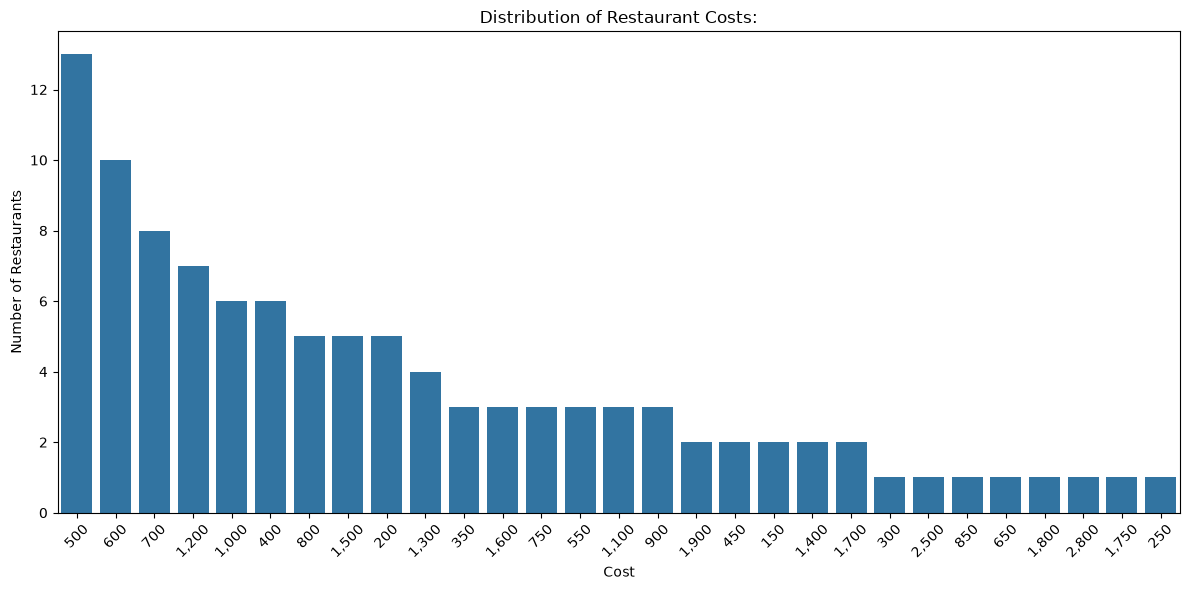

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize= (12,6))
sns.countplot(data = metadata_df, x = "Cost", order = metadata_df["Cost"].value_counts().index)
plt.title("Distribution of Restaurant Costs:")
plt.xlabel("Cost")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

### 4.1.1 Observations and Inferences

- The Cost column contains 29 unique cost values across 105 restaurants.
- The most frequently occurring cost is 500, appearing in 13 restaurants.
- The second and third most frequent values are 600 and 700, respectively.
- The distribution shows a higher concentration of restaurants around the lower and middle cost values.
- Higher cost values occur less frequently, resulting in a distribution with a longer tail towards the higher end.

**Inference:** Restaurant cost may serve as a useful feature for distinguishing restaurants based on their pricing levels during clustering.

### 4.2 Cuisine Analysis

I will investigate the 'Cuisines' column to understand the variety of cuisines offered by the restaurants. I will examine its data type, missing values, unique entries, and common cuisine combinations. This will help me understand how cuisine information is represented and how it can be transformed into useful features for clustering.

In [20]:
print("Data Type of Cuisines:", metadata_df["Cuisines"].dtype)
print("Missing Values:", metadata_df["Cuisines"].isna().sum())
print()
print("Number of Unique Cuisine Entries:", metadata_df["Cuisines"].nunique())
print("\nFirst 10 Cuisines:")
display(metadata_df["Cuisines"].head(10))
print("\nFirst 15 Unique entries:")
display(metadata_df["Cuisines"].dropna().unique()[:15])

Data Type of Cuisines: str
Missing Values: 0

Number of Unique Cuisine Entries: 92

First 10 Cuisines:


0    Chinese, Continental, Kebab, European, South I...
1                       Biryani, North Indian, Chinese
2         Asian, Mediterranean, North Indian, Desserts
3    Biryani, North Indian, Chinese, Seafood, Bever...
4    Asian, Continental, North Indian, Chinese, Med...
5      Seafood, Goan, North Indian, Continental, Asian
6    Healthy Food, North Indian, Continental, South...
7                                             Lebanese
8    American, Chinese, North Indian, Kebab, South ...
9                                  Ice Cream, Desserts
Name: Cuisines, dtype: str


First 15 Unique entries:


<ArrowStringArray>
['Chinese, Continental, Kebab, European, South Indian, North Indian',
                                    'Biryani, North Indian, Chinese',
                      'Asian, Mediterranean, North Indian, Desserts',
                'Biryani, North Indian, Chinese, Seafood, Beverages',
          'Asian, Continental, North Indian, Chinese, Mediterranean',
                   'Seafood, Goan, North Indian, Continental, Asian',
             'Healthy Food, North Indian, Continental, South Indian',
                                                          'Lebanese',
              'American, Chinese, North Indian, Kebab, South Indian',
                                               'Ice Cream, Desserts',
                              'Street Food, North Indian, Fast Food',
                           'Mediterranean, North Indian, Kebab, BBQ',
                                    'Continental, American, Chinese',
                                'North Indian, Italian, Finger Food',
 

In [21]:
# Splitting combines cuisines
cuisine_list = metadata_df["Cuisines"].str.split(",").explode().str.strip()

# Frequency of the cusisines
cuisine_freq = cuisine_list.value_counts()
print("Total Cuisine occurence:", len(cuisine_list))
print("Number of Unique cuisines: ", cuisine_list.nunique())
print("\nTop 20 most common cuisines:", cuisine_freq.head(20))

Total Cuisine occurence: 313
Number of Unique cuisines:  44

Top 20 most common cuisines: Cuisines
North Indian     61
Chinese          43
Continental      21
Biryani          16
Asian            15
Fast Food        15
Italian          14
Desserts         13
South Indian      9
Bakery            7
Kebab             6
American          6
Mughlai           6
Andhra            6
Cafe              6
Mediterranean     5
Beverages         5
Burger            5
Salad             5
European          4
Name: count, dtype: int64


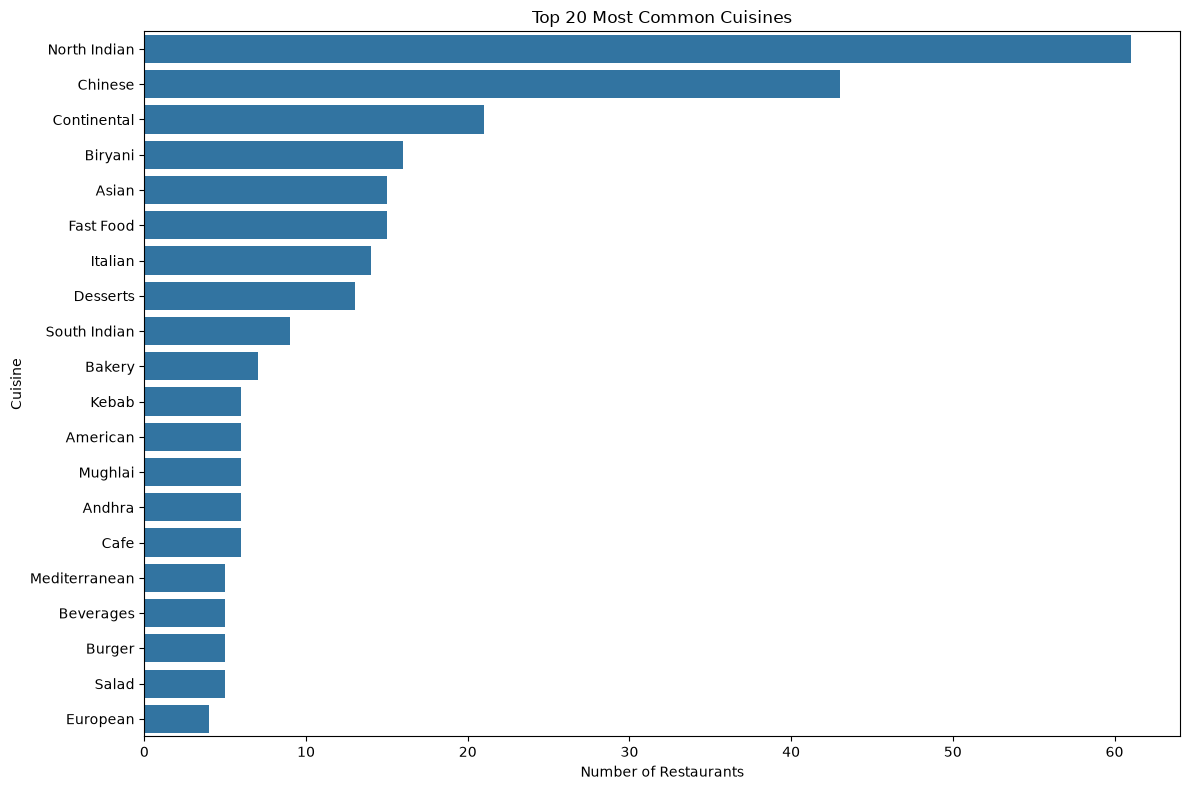

In [22]:
top_20 = cuisine_freq.head(20)
plt.figure(figsize = (12,8))
sns.barplot(x = top_20.values, y = top_20.index)
plt.title("Top 20 Most Common Cuisines")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine")
plt.tight_layout()
plt.show()

#### 4.2.1 Observations and Inferences

- The dataset contains 313 individual cuisine occurrences across 105 restaurants.
- There are 44 distinct individual cuisines and 92 unique cuisine combinations.
- North Indian is the most frequently listed cuisine, appearing in 61 restaurants.
- Chinese ranks second with 43 occurrences, followed by Continental with 21.
- Biryani, Asian, Fast Food, and Italian are also among the commonly listed cuisines.
- The distribution shows that a few cuisines are considerably more common than others.

**Inference:** Cuisine information can be a useful feature for distinguishing restaurants based on their food offerings during clustering.

### 4.3 Collections Analysis

I will investigate the 'Collections' column to understand the different collections associated with restaurants. I will examine its data type, missing values, unique entries, and frequently occurring collections. Since this column contains a considerable number of missing values, I will also assess its completeness before deciding how to use it during feature engineering.

In [23]:
print("Data Type of Collections:", metadata_df["Collections"].dtype)
print("Missing Values:", metadata_df["Collections"].isna().sum())
print("Missing Value Percentage: ", round(metadata_df["Collections"].isna().mean() * 100, 2), "%")
print()
print("Number of Unique Collection Entries: ", metadata_df["Collections"].nunique())
print()
print("First 15 Non-Missing Collection Entries:")
display(metadata_df["Collections"].dropna().head(15))
print()
print("Top 15 Most Common Collectio Entries:")
display(metadata_df["Collections"].value_counts().head(15))

Data Type of Collections: str
Missing Values: 54
Missing Value Percentage:  51.43 %

Number of Unique Collection Entries:  42

First 15 Non-Missing Collection Entries:


0     Food Hygiene Rated Restaurants in Hyderabad, C...
1                                   Hyderabad's Hottest
2                    Great Buffets, Hyderabad's Hottest
3                                Late Night Restaurants
4     Best Bars & Pubs, Food Hygiene Rated Restauran...
5     Sunday Brunches, Corporate Favorites, Great Bu...
6           Food Hygiene Rated Restaurants in Hyderabad
8     Great Buffets, Live Sports Screenings, Best Ba...
9                                       Frozen Delights
10        Street Food, Veggie Friendly, Pocket Friendly
11                                     Barbecue & Grill
12                                        Great Buffets
13    Corporate Favorites, Happy Hours, Live Sports ...
14    Barbecue & Grill, Great Buffets, Corporate Fav...
18                                   Trending This Week
Name: Collections, dtype: str


Top 15 Most Common Collectio Entries:


Collections
Food Hygiene Rated Restaurants in Hyderabad                                                                                                       4
Hyderabad's Hottest                                                                                                                               2
Great Buffets                                                                                                                                     2
Trending This Week                                                                                                                                2
Veggie Friendly                                                                                                                                   2
Pan-Asian Delicacies                                                                                                                              2
New on Gold                                                                                         

In [24]:
# Splitting combines collections into individual collections
collection_list = metadata_df["Collections"].dropna().str.split(",").explode().str.strip()

# Counting individual collection occurrences
collection_freq = collection_list.value_counts()
print("Total Collection Occurrences: ", len(collection_list))
print("Number of Distinct Individual Collections: ", collection_list.nunique())
print()
print("Top 20 Most Common Collections: ")
display(collection_freq.head(20))

Total Collection Occurrences:  106
Number of Distinct Individual Collections:  37

Top 20 Most Common Collections: 


Collections
Great Buffets                                  11
Food Hygiene Rated Restaurants in Hyderabad     8
Live Sports Screenings                          7
Hyderabad's Hottest                             7
Corporate Favorites                             6
Top-Rated                                       5
Gold Curated                                    5
Trending This Week                              5
Best Bars & Pubs                                4
Sunday Brunches                                 4
Veggie Friendly                                 4
Barbecue & Grill                                3
Happy Hours                                     3
Gigs and Events                                 3
Late Night Restaurants                          2
Rooftops                                        2
Fancy and Fun                                   2
Great Breakfasts                                2
Function Venues                                 2
Pan-Asian Delicacies                  

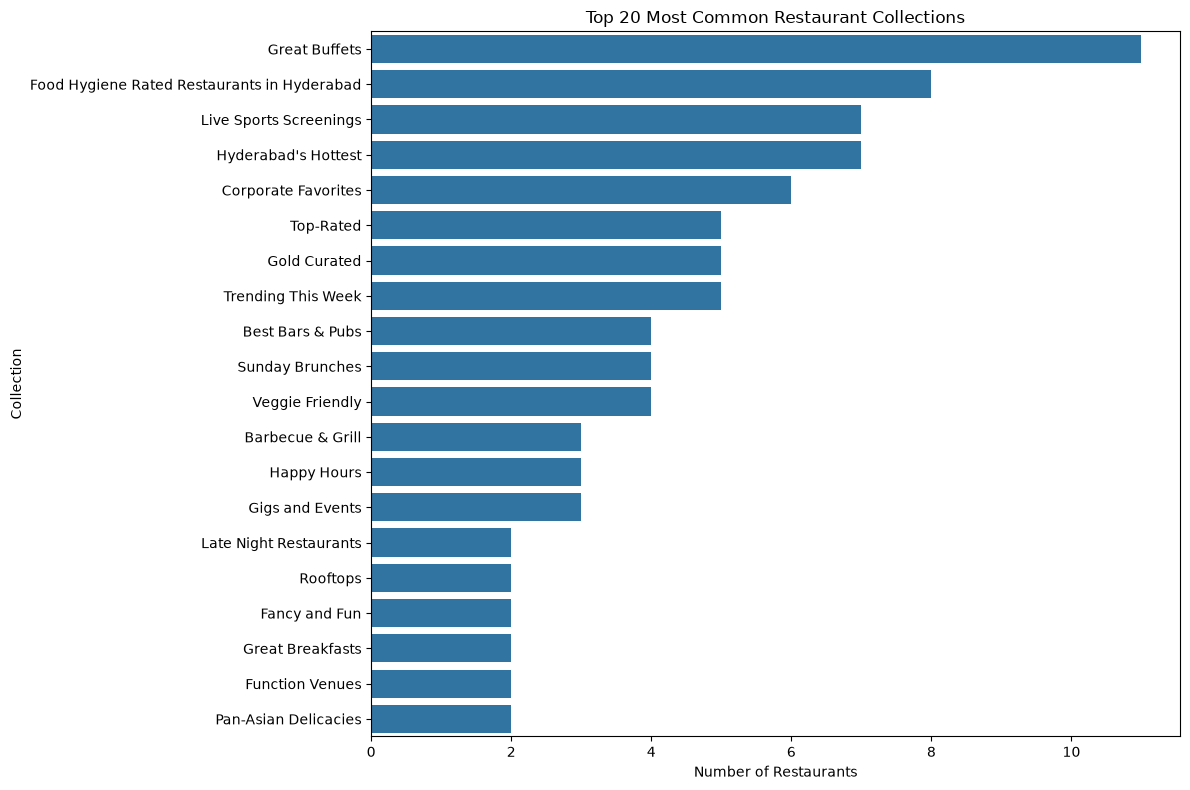

In [25]:
top_20_collections = collection_freq.head(20)
plt.figure(figsize= (12, 8))
sns.barplot(x= top_20_collections.values, y= top_20_collections.index)
plt.title("Top 20 Most Common Restaurant Collections")
plt.xlabel("Number of Restaurants")
plt.ylabel("Collection")
plt.tight_layout()
plt.show()

#### 4.3.1 Observations and Inferences

- The Collections column contains 54 missing values out of 105 restaurants, representing approximately 51.43% missing data.
- After excluding missing values and separating individual collections, I identified 106 collection occurrences across 51 restaurants.
- The dataset contains 37 distinct individual collections.
- Great Buffets is the most frequently occurring collection, appearing 11 times.
- Food Hygiene Rated Restaurants in Hyderabad ranks second with 8 occurrences.
- Live Sports Screenings and Hyderabad's Hottest follow with 7 occurrences each.
- Several collections occur relatively infrequently, indicating a diverse range of restaurant categories and experiences.

**Inference:** Collections may provide useful information about restaurant categories and experiences. However, the high proportion of missing values needs careful consideration before using this feature for clustering.

### 4.4 Timings Analysis

I will investigate the 'Timings' column to understand the operating hours of the restaurants. I will examine its data type, missing values, unique entries, and the format in which operating hours are recorded. This will help me determine whether the information can be transformed into useful numerical features for clustering.

In [26]:
print("Data Type of Timings: ", metadata_df["Timings"].dtype)
print("Missing Values: ", metadata_df["Timings"].isna().sum())
print("Number of Unique Timing Entries: ", metadata_df["Timings"].nunique())
print("\nFirst 10 Timing Entries: ")
display(metadata_df["Timings"].head(10))
print("\nFirst 15 Unique Unique Timing Entries:")
display(metadata_df["Timings"].dropna().unique()[:15])

Data Type of Timings:  str
Missing Values:  1
Number of Unique Timing Entries:  77

First 10 Timing Entries: 


0        12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)
1                                       11 AM to 11 PM
2                11:30 AM to 4:30 PM, 6:30 PM to 11 PM
3                                      12 Noon to 2 AM
4    12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no...
5    12Noon to 3:30PM, 4PM to 6:30PM, 7PM to 11:30P...
6                                        7 AM to 10 PM
7                               12 Noon to 12 Midnight
8                               12 Noon to 12 Midnight
9    10 AM to 1 AM (Mon-Thu), 10 AM to 1:30 AM (Fri...
Name: Timings, dtype: str


First 15 Unique Unique Timing Entries:


<ArrowStringArray>
[                                                                                          '12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)',
                                                                                                                          '11 AM to 11 PM',
                                                                                                   '11:30 AM to 4:30 PM, 6:30 PM to 11 PM',
                                                                                                                         '12 Noon to 2 AM',
                                                                '12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12noon to 12midnight (Fri-Sat)',
 '12Noon to 3:30PM, 4PM to 6:30PM, 7PM to 11:30PM (Mon, Tue, Wed, Thu, Sun), 12Noon to 3:30PM, 4PM to 6:30PM, 7PM to 12Midnight (Fri-Sat)',
                                                                                                                           '7 AM to 10 PM',
 

In [27]:
# Excluding missing data
timings = metadata_df["Timings"].dropna()

# Studying different time patterns
days = timings.str.contains(r"\(", regex=True)
intervals = timings.str.count(" to ") > 1
midnight = timings.str.contains("midnight", case=False)

print("Entries specifying days: ", days.sum())
print("Entries with multiple intervals: ", intervals.sum())
print("Entries mentioning midnight: ", midnight.sum())

# Displaying the results
print("\nFirst 10 Day-specific entries: ")
display(timings[days].head(10))
print("\nFirst 10 Multiple time intervals: ")
display(timings[intervals].head(10))
print("\nFirst 10 Midnight mentions: ")
display(timings[midnight].head(10))

Entries specifying days:  33
Entries with multiple intervals:  36
Entries mentioning midnight:  26

First 10 Day-specific entries: 


0         12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)
4     12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no...
5     12Noon to 3:30PM, 4PM to 6:30PM, 7PM to 11:30P...
9     10 AM to 1 AM (Mon-Thu), 10 AM to 1:30 AM (Fri...
13                       12noon to 12midnight (Mon-Sun)
20              12:30 PM to 10 PM (Tue-Sun), Mon Closed
22    11am to 11:30pm (Mon, Tue, Wed, Thu, Sun), 11a...
24    12 Noon to 12 Midnight (Mon-Thu, Sun), 12 Noon...
25    12Noon to 11PM (Mon-Thu),12Noon to 11:30PM (Fr...
26    12 Noon to 11:30 PM (Mon-Wed), 12 Noon to 1 AM...
Name: Timings, dtype: str


First 10 Multiple time intervals: 


0         12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)
2                 11:30 AM to 4:30 PM, 6:30 PM to 11 PM
4     12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no...
5     12Noon to 3:30PM, 4PM to 6:30PM, 7PM to 11:30P...
9     10 AM to 1 AM (Mon-Thu), 10 AM to 1:30 AM (Fri...
10                 12 Noon to 3:30 PM, 7 PM to 10:30 PM
11              12 Noon to 3:30 PM, 6:30 PM to 11:30 PM
14              12 Noon to 4:30 PM, 6:30 PM to 11:30 PM
21                      11:30 AM to 3 PM, 7 PM to 11 PM
22    11am to 11:30pm (Mon, Tue, Wed, Thu, Sun), 11a...
Name: Timings, dtype: str


First 10 Midnight mentions: 


4     12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no...
5     12Noon to 3:30PM, 4PM to 6:30PM, 7PM to 11:30P...
7                                12 Noon to 12 Midnight
8                                12 Noon to 12 Midnight
13                       12noon to 12midnight (Mon-Sun)
18                               12 Noon to 12 Midnight
22    11am to 11:30pm (Mon, Tue, Wed, Thu, Sun), 11a...
24    12 Noon to 12 Midnight (Mon-Thu, Sun), 12 Noon...
26    12 Noon to 11:30 PM (Mon-Wed), 12 Noon to 1 AM...
31                                 11 AM to 12 Midnight
Name: Timings, dtype: str

#### 4.4.1 Observations and Inferences

- Out of 104 non-missing timing entries, 33 contain parenthetical information, mostly specifying particular days or variations in operating schedules.
- 36 entries contain multiple time intervals, indicating that some restaurants operate during separate shifts, such as lunch and dinner.
- 26 entries explicitly mention midnight, highlighting the variation in closing times and time representations.
- Operating hours are recorded in inconsistent formats, with variations in capitalization, spacing, and expressions such as 12noon, 12 Noon, and 12midnight.

**Inference:** Although operating hours may provide useful information about restaurant availability and operating patterns, extracting reliable numerical features from this column would require substantial text normalization and parsing. I will retain this information for reference but avoid directly using the raw timings in the clustering model.

### 4.5 Review Dataset Analysis

The reviews dataset contains customer feedback, ratings, reviewer information, and other attributes that may help describe restaurant performance and customer experience. I will investigate the relevant review-related features to identify information that can be aggregated at the restaurant level for clustering.

### 4.5.1 Rating Analysis

The 'Rating' column was examined during the Data Quality Assessment section, where I identified its data type, missing values, unique values, and frequency distribution. The ratings are stored as strings and include numerical values ranging from 1 to 5, half-star ratings, and one unusual entry (Like).

I will visualize the rating distribution to better understand how ratings are spread across the dataset and identify the dominant rating values. This will also help determine how ratings can be aggregated at the restaurant level and used as features for clustering.

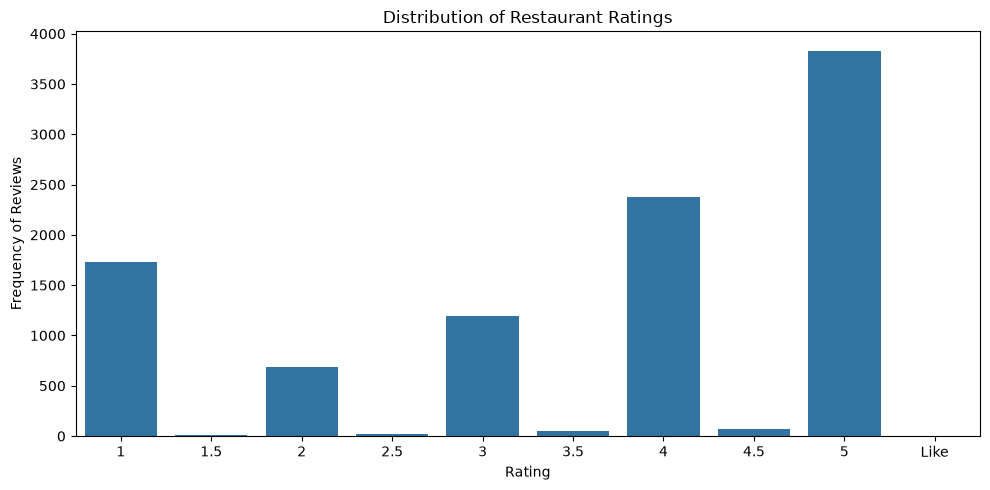

In [28]:
# Distribution
ratings = ["1","1.5","2","2.5","3","3.5","4","4.5","5","Like"]
plt.figure(figsize=(10,5))
sns.countplot(data=reviews_df, x= "Rating", order= ratings)

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency of Reviews")
plt.tight_layout()
plt.show()

### 4.5.2 Review Analysis

I will investigate the Review column to understand the nature of customer feedback, its completeness, and the variation in review length and content. This will help me determine whether textual information can be transformed into useful features for restaurant clustering.

In [29]:
# Inspection of text
print("Data Type of Review: ", reviews_df["Review"].dtype)
print("Missing Values: ", reviews_df["Review"].isna().sum())
print("Number of Unique Reviews: ", reviews_df["Review"].nunique())
print("\nSample Reviews: ")
display(reviews_df["Review"].dropna().sample(10, random_state=42))

Data Type of Review:  str
Missing Values:  45
Number of Unique Reviews:  9364

Sample Reviews: 


4085    Was here with my colleagues. The service was e...
3146    Went there a week ago. The foods were average ...
5488    the food was very bad. the noodles was blant. ...
1253    The place where to dine finely and with good a...
5565    A must visit cafe with an amazing range of cak...
1496    Food is pretty good here and the service is ju...
789     Chicken in the shawarma is stale and stinking....
2020    I have ordered food from this well known parat...
7393    It has been my default place after my rides. G...
7706    I booked The Lime for catering for a private o...
Name: Review, dtype: str

In [30]:
# Word Count of reviews
review_wc = reviews_df["Review"].dropna().str.split().str.len()

# Calculations
print("Average Word Count: ", round(review_wc.mean(),2))
print("Word Count Median: ", review_wc.median())
print("Shortest Review Word: ", review_wc.min())
print("Longest Review Word: ", review_wc.max())
print("\nWord Count Statistics: ")
display(review_wc.describe())

Average Word Count:  50.17
Word Count Median:  34.0
Shortest Review Word:  1
Longest Review Word:  964

Word Count Statistics: 


count    9955.000000
mean       50.173079
std        60.783718
min         1.000000
25%        24.000000
50%        34.000000
75%        58.000000
max       964.000000
Name: Review, dtype: float64

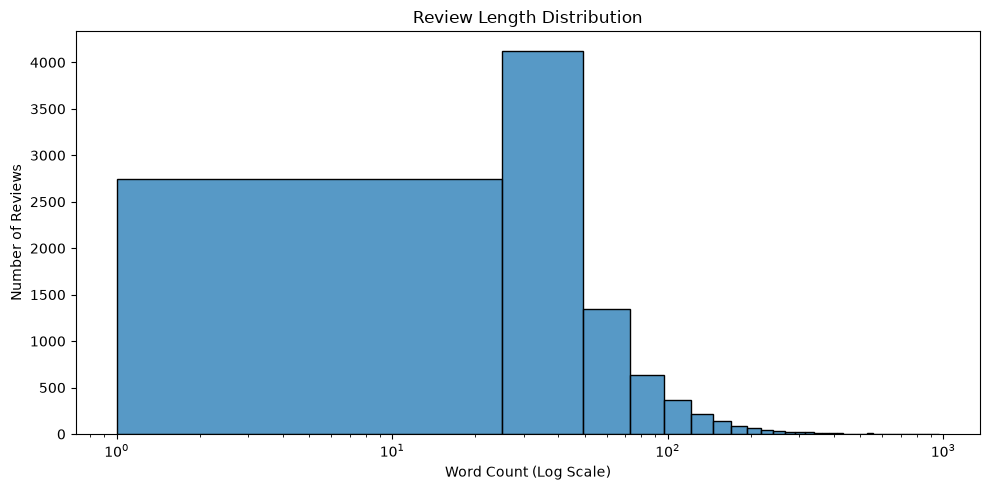

Numerical Summary: 


Review
(0, 10]        1763
(10, 20]        315
(20, 30]       2103
(30, 50]       2775
(50, 100]      1958
(100, 200]      772
(200, 500]      244
(500, 1000]      25
Name: count, dtype: int64

In [31]:
# Length Distribution
plt.figure(figsize=(10,5))
sns.histplot(review_wc, bins = 40)
plt.xscale("log")
plt.title("Review Length Distribution")
plt.xlabel("Word Count (Log Scale)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

# Numerical Summary
bins = [0, 10, 20, 30, 50, 100, 200, 500, 1000]
review_length = pd.cut(review_wc, bins=bins)
print("Numerical Summary: ")
display(review_length.value_counts().sort_index())

##### 4.5.2.1 Observations and Inferences

- The dataset contains 9,955 non-missing reviews, with an average length of approximately 50 words and a median of 34 words.
- The mean is higher than the median, indicating a right-skewed distribution of review lengths.
- The largest group of reviews (2,775) contains between 30 and 50 words, followed by 2,103 reviews containing between 20 and 30 words.
- A substantial number of reviews are relatively short, with 1,763 reviews containing 10 words or fewer.
- 1,041 reviews exceed 100 words, while only 25 reviews exceed 500 words.
- Review lengths vary considerably, with the longest review containing 964 words.

**Inference:** Most customer reviews contain a moderate amount of text, while a smaller number provide considerably more detail. Review text may contain useful information about customer experiences, food quality, service, and other restaurant attributes. However, incorporating raw text into clustering would require additional processing and feature extraction. I will explore the potential for deriving meaningful text-based features during feature engineering rather than directly using raw review text.

### 4.5.3 Reviewer Analysis

I will examine the `Reviewer` column to understand the number of unique reviewers, the presence of repeated reviewers, and the distribution of reviews across reviewers. This will help me determine whether reviewer-related information can contribute useful features to restaurant-level clustering or should be excluded from the analysis.

In [32]:
print("Data Type of Reviewer: ", reviews_df["Reviewer"].dtype)
print("Missing Values: ", reviews_df["Reviewer"].isna().sum())
print("Unique Reviewers: ", reviews_df["Reviewer"].nunique())
print("\nSample Reviewers: ")
display(reviews_df["Reviewer"].dropna().sample(10, random_state=42))
print("\nMost Frequent Reviewers: ")
display(reviews_df["Reviewer"].value_counts().head(10))


Data Type of Reviewer:  str
Missing Values:  38
Unique Reviewers:  7446

Sample Reviewers: 


6448     Purandhar Bandaru
6831         Rahul Agarwal
8451           Kiran Thota
39           Sai Raj Kiran
7458               Keerthi
3776    Buvanala Ravikumar
2069     Taranddeep Singgh
4347                Praful
3936    Nishant Srivastava
568                  Siddu
Name: Reviewer, dtype: str


Most Frequent Reviewers: 


Reviewer
Ankita                            13
Parijat Ray                       13
Kiran                             12
Vedant Killa                      11
Jay Mehta                         11
Sravani                           10
Manojkumar D Nambisan             10
Priyanka                          10
Age Of Foodies (Suraj Karambe)    10
Siva Kumar                        10
Name: count, dtype: int64

##### 4.5.3.1 Observations and Inferences

- The 'Reviewer' column contains 38 missing values and 7,446 unique reviewers.
- The dataset exhibits substantial reviewer diversity, with most reviewers contributing relatively few reviews.
- The most frequent reviewers have contributed only 10–13 reviews each.

**Inference:** 'Reviewer' names are identifiers and do not directly describe restaurant characteristics. Given the high diversity of reviewers and limited repeat contributions, individual reviewer identities are not useful features for restaurant-level clustering. I will exclude the 'Reviewer' column from feature engineering while retaining the associated review records for restaurant-level analysis.

### 4.5.4 Metadata Analysis

I will investigate the 'Metadata' column to understand its structure, completeness, and the type of information it contains. This will help me determine whether it can be transformed into meaningful features for restaurant-level clustering.

In [33]:
print("Data Type of Metadata: ", reviews_df["Metadata"].dtype)
print("Missing Values: ", reviews_df["Metadata"].isna().sum())
print("Unique Metadata Entries: ", reviews_df["Metadata"].nunique())
print("\nSample Entries: ")
display(reviews_df["Metadata"].dropna().sample(10, random_state=42))

# Frequency
print("Frequency of Metadata Entries:")
display(reviews_df["Metadata"].value_counts().head(20))



Data Type of Metadata:  str
Missing Values:  38
Unique Metadata Entries:  2477

Sample Entries: 


6448                      1 Review
6831    34 Reviews , 233 Followers
8451    78 Reviews , 117 Followers
39          2 Reviews , 1 Follower
7458                      1 Review
3776      0 Reviews , 20 Followers
2069                      1 Review
4347     97 Reviews , 97 Followers
3936        3 Reviews , 1 Follower
568       10 Reviews , 3 Followers
Name: Metadata, dtype: str

Frequency of Metadata Entries:


Metadata
1 Review                   919
1 Review , 1 Follower      750
2 Reviews , 1 Follower     337
2 Reviews                  262
1 Review , 2 Followers     227
3 Reviews , 1 Follower     173
2 Reviews , 2 Followers    138
3 Reviews                  131
4 Reviews , 1 Follower     111
0 Reviews                   95
3 Reviews , 2 Followers     92
1 Review , 3 Followers      84
5 Reviews , 1 Follower      66
1 Review , 4 Followers      60
4 Reviews                   57
2 Reviews , 3 Followers     56
4 Reviews , 2 Followers     56
3 Reviews , 3 Followers     50
6 Reviews , 1 Follower      46
5 Reviews                   46
Name: count, dtype: int64

##### 4.5.4.1 Observations and Inferences

- The Metadata column primarily contains reviewer statistics, including the number of reviews written and followers accumulated.
- The most frequent entries are 1 Review (919 records) and 1 Review, 1 Follower (750 records).
- Most entries represent reviewers with relatively few reviews and followers, although the column contains considerable variation.
- The metadata is associated with individual reviewers rather than restaurants.

**Inference:** The Metadata column provides information about reviewer activity but does not directly describe restaurant characteristics. I will exclude it from restaurant-level clustering while retaining the review records for extracting relevant restaurant-level features.

### 4.5.5 Time Analysis

I will examine the Time column to understand the format of review timestamps, the time span covered by the dataset, and the distribution of review records over time. This will help determine whether temporal information can be used to derive meaningful features for restaurant-level clustering.

In [34]:
print("Data Type of TIme: ", reviews_df["Time"].dtype)
print("Missing Values: ", reviews_df["Time"].isna().sum())
print("Unique Time Entries: ", reviews_df["Time"].nunique())
print("\nSample Time Entries: ")
display(reviews_df["Time"].dropna().sample(10,random_state=42))

Data Type of TIme:  str
Missing Values:  38
Unique Time Entries:  9782

Sample Time Entries: 


6448    7/23/2018 21:53
6831     3/16/2019 6:56
8451    6/26/2018 22:18
39      5/18/2019 15:54
7458     9/2/2018 22:28
3776    7/28/2018 14:00
2069    9/29/2018 20:57
4347    9/20/2018 11:58
3936     1/25/2019 0:32
568      3/31/2019 0:32
Name: Time, dtype: str

In [35]:
# Convert timestamps to datetime 
review_time = pd.to_datetime(reviews_df["Time"], errors="coerce")

# Validate conversion and inspect date range
print("Failed Conversion(s): ", review_time.isna().sum())
print("\nEarliest Review: ", review_time.min())
print("\nLatest Review: ", review_time.max())

Failed Conversion(s):  38

Earliest Review:  2016-05-31 16:41:00

Latest Review:  2019-05-25 20:23:00


##### 4.5.5.1 Monthly Review Distribution

I will examine the number of reviews submitted each month throughout the dataset's time span. This will help me identify variations in review activity, periods with relatively high or low review volumes, and potential temporal patterns in the data.

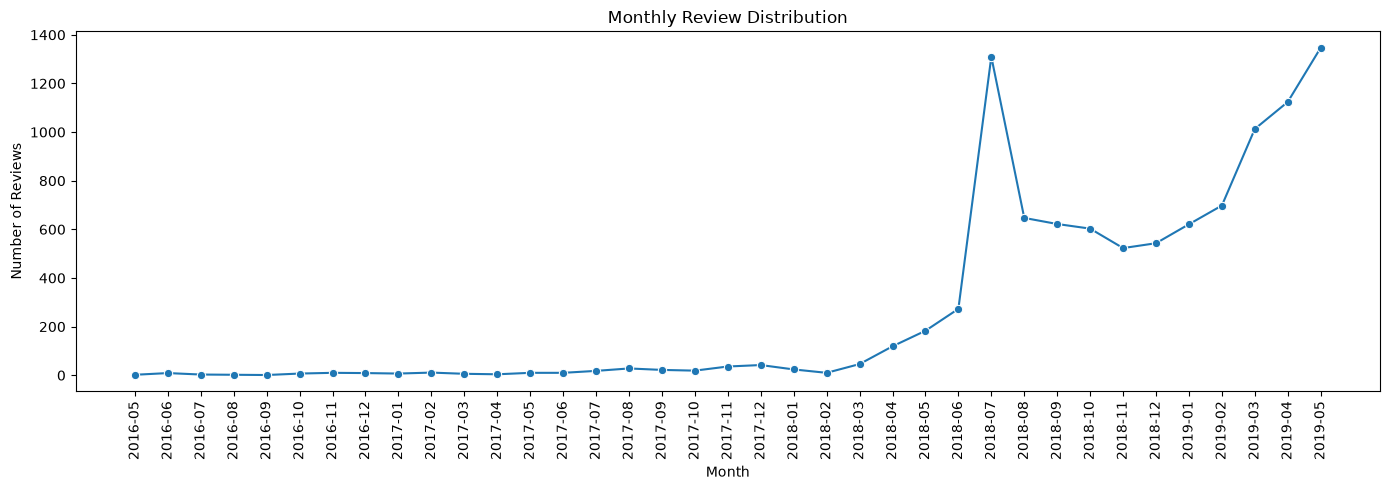

In [36]:
monthly = review_time.dropna().dt.to_period("M").value_counts().sort_index()

# Distribution
plt.figure(figsize=(14,5))
sns.lineplot(x=monthly.index.astype(str), y=monthly.values, marker = "o")
plt.title("Monthly Review Distribution")
plt.xlabel("Month")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

##### 4.5.5.2 Observations and Inferences

- The review dataset spans approximately three years, from May 2016 to May 2019.
- Review activity remained relatively low during the initial period, from May 2016 to December 2017, with monthly counts generally below 50.
- Review volume began increasing during the first half of 2018, reaching approximately 270 reviews in June.
- A sharp spike was observed in July 2018, with approximately 1,310 reviews, followed by a considerable decline in the subsequent months.
- Review activity increased again during 2019, reaching approximately 1,350 reviews in May, the highest monthly count observed in the dataset.

**Inference:** The dataset exhibits considerable temporal variation in review volume, with a general increase toward the later part of the observed period. Although temporal information could be used to derive features such as review recency or review activity, the observed trend may also be influenced by the dataset's sampling and collection process. Therefore, the monthly distribution should not be interpreted as a direct representation of overall Zomato customer engagement.

### 4.5.6 Pictures Analysis

I will examine the Pictures column to understand the distribution of pictures attached to reviews, determine how frequently reviewers include pictures, and assess whether picture-related information can contribute useful features to restaurant-level clustering.

In [37]:
print("Data Type of Pictures: ", reviews_df["Pictures"].dtype)
print("Missing Values: ", reviews_df["Pictures"].isna().sum())
print("Unique Picture Counts: ", reviews_df["Pictures"].nunique())
print("\nPicture Count Distribution: ")
display(reviews_df["Pictures"].value_counts().sort_index())

Data Type of Pictures:  int64
Missing Values:  0
Unique Picture Counts:  36

Picture Count Distribution: 


Pictures
0     8016
1      707
2      383
3      246
4      129
5      116
6       85
7       86
8       55
9       47
10      35
11       9
12       9
13       6
14       7
15      12
16       4
17       4
18       4
19       4
20       5
21       4
22       4
23       1
24       3
25       2
26       2
27       4
28       2
32       1
34       2
37       1
41       1
42       2
52       1
64       1
Name: count, dtype: int64

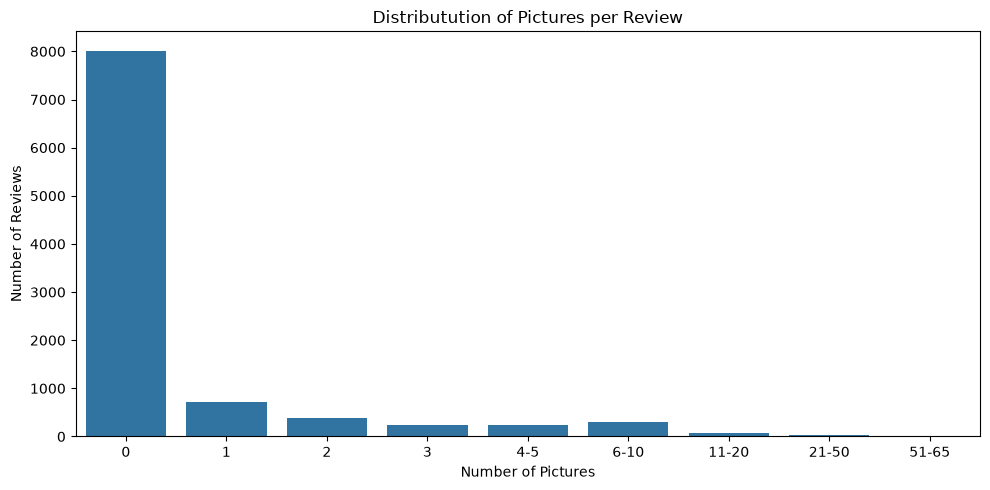

In [38]:
# Picture Counts
picture_bins = [-1,0,1,2,3,5,10,20,50,65]
picture_labels = ["0","1","2","3","4-5","6-10","11-20","21-50","51-65"]
pic_grp = pd.cut(reviews_df["Pictures"], bins=picture_bins, labels=picture_labels)
pic_counts= pic_grp.value_counts().sort_index()

# Visualization
plt.figure(figsize=(10,5))
sns.barplot(x=pic_counts.index, y=pic_counts.values)
plt.title("Distributution of Pictures per Review")
plt.xlabel("Number of Pictures")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

##### 4.5.6.1 Observations and Inferences

- The Pictures column is numerical, contains no missing values, and has 36 unique values.
- A majority of reviews (8,016) contain zero pictures, representing approximately 80.16% of the dataset.
- The number of reviews decreases considerably as the picture count increases. Reviews containing one, two, or three pictures account for 707, 383, and 246 records, respectively.
- Reviews containing 6–10 pictures are relatively uncommon, while reviews containing more than 20 pictures are extremely rare.
- The distribution is highly right-skewed, with a small number of reviews containing unusually high picture counts, reaching a maximum of 64.

**Inference:** Picture uploads are relatively uncommon among reviewers, with most reviews containing no pictures. Picture count may provide an indication of reviewer contribution or engagement, but it is not a direct measure of restaurant quality. I may consider aggregating picture-related information at the restaurant level during feature engineering, although its usefulness for clustering will need to be evaluated.

## 5. Data Understanding Summary

In this notebook, I explored the restaurant metadata and review datasets to understand their structure, quality, characteristics, and potential relevance to the clustering objective.

The analysis helped identify data quality issues, understand the relationship between the two datasets, investigate individual features, and determine which attributes may be useful for restaurant-level segmentation.

The following summarizes the key findings and considerations that will guide the subsequent data preparation and feature engineering stages.

### 5.1 Dataset Overview

The project consists of two datasets containing restaurant information and customer reviews.

| Dataset | Records | Features | Description |
|---|---:|---:|---|
| Restaurant Metadata | 105 | 6 | Restaurant names, cost, cuisines, collections, timings, and links |
| Restaurant Reviews | 10,000 | 7 | Restaurant reviews, ratings, reviewer information, timestamps, and picture counts |

The metadata dataset provides restaurant-level information, while the reviews dataset contains individual customer review records. The two datasets share restaurant names, allowing review-related information to be aggregated and combined with restaurant metadata to create a unified restaurant-level dataset.

### 5.2 Key Data Quality Findings

During the initial investigation, I identified the following issues and characteristics:

- **Missing values:** Missing values exist in several columns, particularly Collections in the metadata dataset and reviewer-related fields in the reviews dataset.
- **Duplicate records:** Duplicate review records were identified and will need to be addressed during data preparation.
- **Placeholder records:** Some review records contain restaurant names but lack actual review information. These will need to be handled before deriving review-based features.
- **Inconsistent data types:** Several numerical attributes, such as restaurant cost and ratings, are stored as strings and require conversion.
- **Inconsistent formatting:** Cuisines, collections, and timings contain variations in formatting and representation.
- **Unusual values:** The rating column contains an atypical entry (Like) alongside numerical ratings and half-star ratings.
- **Complex timing information:** Restaurant opening hours contain inconsistent formats, multiple time intervals, and day-specific schedules, making direct parsing difficult.

### 5.3 Feature Potential and Future Considerations

The initial investigation revealed several attributes that may contribute to meaningful restaurant segmentation.

| Feature | Potential Use | Considerations |
|---|---|---|
| Cost | Represent restaurant affordability and pricing | Convert to numerical values |
| Cuisines | Capture restaurant food categories and variety | Split into individual cuisines and encode |
| Collections | Capture restaurant categories, popularity, or experiences | High missingness; may require careful handling |
| Ratings | Represent customer satisfaction | Convert to numerical values and aggregate at restaurant level |
| Review Text | Extract customer opinions and experience-related information | Requires text processing or sentiment feature extraction |
| Review Time | Capture review activity and temporal characteristics | Aggregate appropriately; sampling trends may affect interpretation |
| Pictures | Represent picture contribution or review activity | Aggregate at restaurant level; evaluate usefulness |
| Timings | Represent operating schedules | Complex formatting; parsing may not be worthwhile |

Reviewer names and metadata primarily describe reviewer activity rather than restaurants. They are unlikely to be useful directly for restaurant-level clustering and will therefore not be considered direct clustering features.

The review text may provide additional insights into food quality, service, ambiance, and customer experience. However, incorporating text-derived information will require additional processing and evaluation.

These potential features will be revisited during data preparation and feature engineering, where their suitability for restaurant-level clustering will be assessed.

### 5.4 Challenges and Limitations

The datasets present several challenges that may influence the clustering results:

- The review dataset contains a fixed number of records per restaurant, which may not reflect the actual volume of customer reviews or popularity.
- Some restaurants present in the metadata dataset do not have corresponding reviews, resulting in incomplete review-derived features.
- Missing values, duplicate records, and placeholder entries require appropriate handling.
- Review ratings and text may reflect subjective customer experiences and varying levels of reviewer activity.
- Categorical attributes such as cuisines and collections require suitable encoding or transformation.
- Text-derived features may introduce additional complexity and dimensionality.
- The dataset represents a limited collection of restaurants and a specific historical period, so the resulting clusters may not generalize to all restaurants or reflect current restaurant characteristics.

These limitations will be considered during data preparation, feature engineering, clustering, and interpretation of the final results.